<a href="https://colab.research.google.com/github/EthanFerba/IDX-Exchange-Data-Science/blob/main/First_Modelp2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# First import the libaries
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

Import the data frame

In [2]:
rdf = pd.read_csv("Completedf.csv")
print("Dataset shape:", rdf.shape)
rdf.head()

Dataset shape: (65782, 46)


,ClosePrice,Latitude,Longitude,PropertyType,LivingArea,CloseDate,ListPrice,DaysOnMarket,ListOfficeName,ListingContractDate,...,Flooring_Tile,Flooring_Vinyl,Flooring_Wood,Flooring_Missing,Flooring_SeeRemarks,Log_ClosePrice,Log_ListPrice,Log_LivingArea,Log_LotSizeSquareFeet,Log_LotSizeArea
0,640000.0,34.235979,-117.202269,Residential,2070.0,2022-01-10,565000.0,13.0,Label Realty Group,2021-10-12,...,0,0,0,1,0,13.369225,13.244583,7.635787,8.130942,8.130942
1,438000.0,34.114130,-117.442493,Residential,1174.0,2022-03-23,349999.0,3.0,INTERNATIONAL REAL ESTATE SVCS,2021-10-13,...,0,0,0,1,0,12.989976,12.765688,7.069023,9.200391,9.200391
2,399990.0,39.767729,-121.586400,Residential,1422.0,2022-01-19,399990.0,63.0,"3Tree Realty, Inc.",2021-04-09,...,0,0,0,1,0,12.899197,12.899197,7.260523,9.409027,9.409027
3,1050000.0,34.164901,-118.319259,Residential,1312.0,2022-03-08,1103000.0,33.0,"Ingenious Asset Group, Inc.",2021-10-13,...,0,0,0,0,0,13.864302,13.913545,7.180070,8.875287,8.875287
4,275000.0,34.405539,-116.948065,Residential,1578.0,2022-03-29,272500.0,98.0,Dynasty Real Estate,2021-10-13,...,0,1,0,0,0,12.524530,12.515398,7.364547,10.244450,10.244450


Just doing a double check to make sure that everything is looking the way I want it too

In [3]:
rdf.isna().mean() * 100

,0
ClosePrice,0.0
Latitude,0.0
Longitude,0.0
PropertyType,0.0
LivingArea,0.0
CloseDate,0.0
ListPrice,0.0
DaysOnMarket,0.0
ListOfficeName,0.0
ListingContractDate,0.0


Use the same splitting function from the data cleaning phase

In [4]:

def create_temporal_split(df, training_months_x):

    df = df.copy()
    df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

    max_close_date = df["CloseDate"].max()
    test_start_date = max_close_date.to_period("M").start_time
    test_end_date = test_start_date + pd.DateOffset(months=1)

    train_start_date = test_start_date - pd.DateOffset(
        months=training_months_x
    )

    train_mask = (
        (df["CloseDate"] >= train_start_date)
        & (df["CloseDate"] < test_start_date)
    )

    test_mask = (
        (df["CloseDate"] >= test_start_date)
        & (df["CloseDate"] < test_end_date)
    )

    df_train = df[train_mask].copy()
    df_test = df[test_mask].copy()

    print(f"--- Split Summary for X = {training_months_x} Months ---")
    print(
        f"Train: {train_start_date.date()} to "
        f"{(test_start_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_train)} rows)"
    )
    print(
        f"Test:  {test_start_date.date()} to "
        f"{(test_end_date - pd.Timedelta(days=1)).date()} "
        f"({len(df_test)} rows)"
    )
    print(f"Missing CloseDate rows: {df['CloseDate'].isna().sum()}\n")

    return df_train, df_test


window_options = [3, 6, 12, 24]

for X in window_options:
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=X
    )


--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0



These are the columns that we do not want to include

In [5]:
# Columns that should not be used as model features
columns_to_drop = [
    "ClosePrice",
    "Log_ClosePrice",
    "CloseDate",
    "PurchaseContractDate",
    "DaysOnMarket",
    "ListingContractDate",
    "ListOfficeName",
    "ListAgentFullName",
    "PropertyType",
    "PropertySubType",
    "ListPrice",
    "Log_ListPrice"
]


In [6]:
window_options = [3, 6, 12, 24]

In [7]:
baseline_results = []

for months in window_options:

    # Split data
    train_set, test_set = create_temporal_split(
        rdf, training_months_x=months
    )

    # Separate target
    y_train = train_set["ClosePrice"]
    y_test = test_set["ClosePrice"]

    # Remove target and leakage columns
    X_train = train_set.drop(
        columns=columns_to_drop, errors="ignore"
    )
    X_test = test_set.drop(
        columns=columns_to_drop, errors="ignore"
    )

    # Keep numerical features only
    X_train = X_train.select_dtypes(include="number")
    X_test = X_test[X_train.columns]

    # Train Linear Regression
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict
    predictions = model.predict(X_test)

    # Evaluate
    test_r2 = r2_score(y_test, predictions)

    # Record results
    baseline_results.append({
        "Training_Months": months,
        "Training_Rows": len(X_train),
        "Testing_Rows": len(X_test),
        "Test_R2": test_r2
    })

    print(f"{months}-month window: R² = {test_r2:.4f}")

--- Split Summary for X = 3 Months ---
Train: 2023-10-01 to 2023-12-31 (24044 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

3-month window: R² = 0.5263
--- Split Summary for X = 6 Months ---
Train: 2023-07-01 to 2023-12-31 (47079 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

6-month window: R² = 0.5310
--- Split Summary for X = 12 Months ---
Train: 2023-01-01 to 2023-12-31 (54273 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

12-month window: R² = 0.5292
--- Split Summary for X = 24 Months ---
Train: 2022-01-01 to 2023-12-31 (58713 rows)
Test:  2024-01-01 to 2024-01-31 (7069 rows)
Missing CloseDate rows: 0

24-month window: R² = 0.5264


Ranked R^2

In [8]:
results_df = pd.DataFrame(baseline_results)

results_df = results_df.sort_values(
    by="Test_R2",
    ascending=False
).reset_index(drop=True)

results_df

,Training_Months,Training_Rows,Testing_Rows,Test_R2
0,6,47079,7069,0.530972
1,12,54273,7069,0.529234
2,24,58713,7069,0.526381
3,3,24044,7069,0.526261


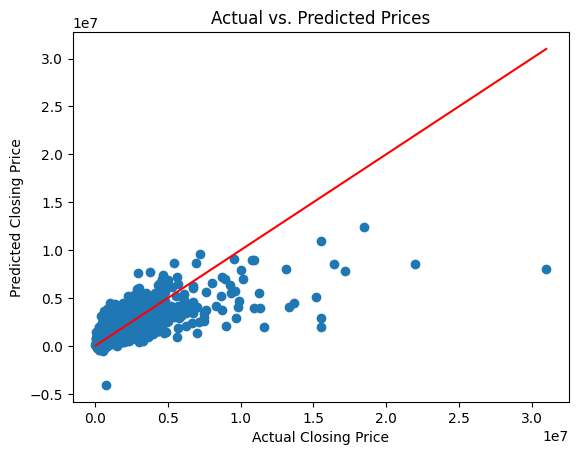

In [14]:
plt.scatter(y_test, predictions)
plt.xlabel("Actual Closing Price")
plt.ylabel("Predicted Closing Price")
plt.title("Actual vs. Predicted Prices")
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)
plt.show()